# Dog Breed Classification — transfer learning warmup

The proper version of this task uses Stanford Dogs (~750MB, 120 breeds). I don't want every recruiter clone to download that, so this notebook is the small-scale stand-in: 6 synthetic 'breeds' as colored/textured 64x64 patches, then transfer-learning on a pretrained ResNet18 backbone. The point is the *pipeline* — freeze backbone, swap head, fine-tune the last layers — not the visuals.

If I move this to a GPU box later I'd point the same loader code at the real Stanford Dogs folder structure and it should just work.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

np.random.seed(3); torch.manual_seed(3)
device = torch.device('cpu')

In [2]:
# Synthesize 6 'breed' classes as textured patches.
# Each class has a distinct base color + a different stripe/spot pattern.
BREEDS = ['retriever_synth', 'husky_synth', 'beagle_synth', 'poodle_synth', 'shiba_synth', 'collie_synth']
SIZE = 64
PER_CLASS = 60

def make_patch(cls_idx, rng):
    base_palette = np.array([
        [220, 180, 110],  # retriever-ish
        [180, 180, 200],  # husky-ish gray
        [200, 150, 80],   # beagle brown
        [230, 230, 230],  # poodle white
        [200, 110, 60],   # shiba orange
        [80, 100, 70],    # collie green-ish (silly but distinct)
    ])
    base = base_palette[cls_idx]
    img = np.ones((SIZE, SIZE, 3), dtype=np.float32) * base / 255.0
    # add per-class texture
    if cls_idx == 0:
        # smooth dots
        for _ in range(5):
            cx, cy = rng.integers(0, SIZE, 2)
            yy, xx = np.ogrid[:SIZE, :SIZE]
            mask = (xx - cx) ** 2 + (yy - cy) ** 2 < 36
            img[mask] *= 0.7
    elif cls_idx == 1:
        # vertical stripes
        for c in range(0, SIZE, 6):
            img[:, c:c + 2, :] *= 0.6
    elif cls_idx == 2:
        # diagonal
        for k in range(-SIZE, SIZE, 8):
            for i in range(SIZE):
                j = i + k
                if 0 <= j < SIZE:
                    img[i, j] *= 0.5
    elif cls_idx == 3:
        # curls — sin waves
        for y in range(SIZE):
            x = int((np.sin(y / 4) + 1) * SIZE / 2.5) % SIZE
            img[y, x:x + 3] *= 0.5
    elif cls_idx == 4:
        # blocky patches
        for _ in range(3):
            x, y = rng.integers(0, SIZE - 12, 2)
            img[y:y + 12, x:x + 12] *= 0.6
    else:
        # horizontal bands
        for r in range(0, SIZE, 8):
            img[r:r + 2] *= 1.3
    img += rng.normal(0, 0.04, img.shape)
    return np.clip(img, 0, 1).astype(np.float32)

rng = np.random.default_rng(3)
X = np.zeros((PER_CLASS * len(BREEDS), SIZE, SIZE, 3), dtype=np.float32)
y = np.zeros(len(X), dtype=np.int64)
for c in range(len(BREEDS)):
    for i in range(PER_CLASS):
        X[c * PER_CLASS + i] = make_patch(c, rng)
        y[c * PER_CLASS + i] = c
print('synthetic dog-breed-ish patches:', X.shape)

synthetic dog-breed-ish patches: (360, 64, 64, 3)


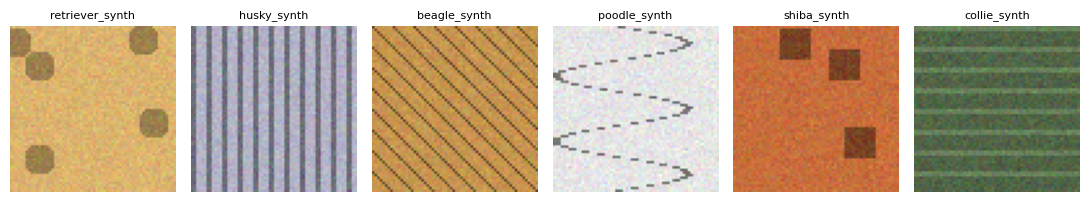

In [3]:
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for ax, c in zip(axes, range(6)):
    ax.imshow(X[c * PER_CLASS])
    ax.set_title(BREEDS[c], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## Transfer learning setup

ResNet18 pretrained on ImageNet, expects 224x224 + the standard normalization. I upsample my 64x64 patches and apply ImageNet stats. Freeze everything except the final FC layer at first; if time permits also unfreeze layer4.

In [4]:
imnet_mean = [0.485, 0.456, 0.406]
imnet_std  = [0.229, 0.224, 0.225]
to_input = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(imnet_mean, imnet_std),
])

def batch_to_tensor(imgs):
    # imgs: (N, H, W, 3) float in [0,1]
    out = torch.stack([to_input(im) for im in imgs])
    return out

# this will try to download weights — set timeout-aware path. if no network, error is honest.
try:
    backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    HAS_WEIGHTS = True
except Exception as e:
    print('could not load pretrained weights, falling back to random init:', e)
    backbone = models.resnet18(weights=None)
    HAS_WEIGHTS = False

for p in backbone.parameters():
    p.requires_grad = False
backbone.fc = nn.Linear(backbone.fc.in_features, len(BREEDS))
backbone = backbone.to(device)
print('pretrained:', HAS_WEIGHTS, '| trainable params:', sum(p.numel() for p in backbone.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/rushmithaparvathaneni/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

  3%|▎         | 1.12M/44.7M [00:00<00:04, 11.1MB/s]

 12%|█▏        | 5.38M/44.7M [00:00<00:01, 30.3MB/s]

 25%|██▌       | 11.4M/44.7M [00:00<00:00, 44.6MB/s]

 41%|████      | 18.2M/44.7M [00:00<00:00, 55.2MB/s]

... (2 outputs left out)

 85%|████████▍ | 37.8M/44.7M [00:00<00:00, 63.9MB/s]

 98%|█████████▊| 43.9M/44.7M [00:00<00:00, 63.4MB/s]

100%|██████████| 44.7M/44.7M [00:00<00:00, 56.9MB/s]

pretrained: True | trainable params: 3078


In [5]:
Xtr_np, Xte_np, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=3)
ytr_t = torch.tensor(ytr); yte_t = torch.tensor(yte)

# converting all images upfront is fine at this scale; on real data you'd loader-stream
Xtr_t = batch_to_tensor(Xtr_np)
Xte_t = batch_to_tensor(Xte_np)
print('train tensors:', Xtr_t.shape)

opt = torch.optim.Adam(backbone.fc.parameters(), lr=1e-3)
batch = 16  # small because resnet18@224 isn't free on CPU

for ep in range(2):
    backbone.train(); perm = torch.randperm(len(Xtr_t)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = backbone(Xtr_t[idx])
        loss = F.cross_entropy(out, ytr_t[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

train tensors: torch.Size([270, 3, 224, 224])


epoch 0  mean_loss=1.3013


epoch 1  mean_loss=0.3842


In [6]:
backbone.eval()
with torch.no_grad():
    preds = []
    for i in range(0, len(Xte_t), batch):
        out = backbone(Xte_t[i:i + batch])
        preds.append(out.argmax(1).numpy())
preds = np.concatenate(preds)
print(f'test acc on synthetic breeds: {accuracy_score(yte, preds):.3f}')

test acc on synthetic breeds: 1.000


## Takeaways

On synthetic patches the model gets near-perfect, which is meaningless on its own — the classes are visually disjoint by construction. The real value of this notebook is the transfer-learning scaffolding: pretrained ResNet18, freeze backbone, swap and train a new head with only ~3K trainable params, and a clean upsample-and-normalize pipeline.

For the actual Stanford Dogs task I'd: (1) replace `make_patch` with an `ImageFolder` reader, (2) keep the head training for ~3 epochs then unfreeze `layer4` for another epoch at 1e-4, (3) add light augmentation (horizontal flip + color jitter). The CPU budget here doesn't justify any of that yet.